# Nolan's actor–film network

In [1]:
from pathlib import Path
import textwrap

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
from IPython.display import Markdown, display

%matplotlib inline

PROJECT = Path.cwd()
if not (PROJECT / "data/nolan/graphs/nolan_bipartite.graphml").is_file():
    PROJECT = PROJECT / "Final project"
GRAPH_FILE = PROJECT / "data/nolan/graphs/nolan_bipartite.graphml"
if not GRAPH_FILE.is_file():
    raise FileNotFoundError("Open this notebook from the repository root or Final project folder.")

FIGURES = PROJECT / "figures"
FIGURES.mkdir(exist_ok=True)

## Load the graph


In [2]:
G_all = nx.read_graphml(GRAPH_FILE)

# Analysis network: drop credits that are not an on-screen part. Voice-only
# and archive-footage credits are not a role in the film, and uncredited
# credits are mostly extras (66 in The Dark Knight Rises alone). Actors left
# with no remaining credit are removed. The full graph is kept as G_all.
EXCLUDE = ("uncredited", "voice", "archive_footage")
G = G_all.copy()
G.remove_edges_from([(a, b) for a, b, d in G_all.edges(data=True)
                     if any(d.get(flag) in (True, "True", "true") for flag in EXCLUDE)])
G.remove_nodes_from([n for n in list(G) if G.degree(n) == 0])
print(f"Full graph: {G_all.number_of_nodes() - 13:,} actors, {G_all.number_of_edges():,} links; "
      f"excluded {G_all.number_of_edges() - G.number_of_edges()} uncredited/voice/archive credits")
actors = sorted(n for n, d in G.nodes(data=True) if d["node_type"] == "actor")
films = sorted(
    (n for n, d in G.nodes(data=True) if d["node_type"] == "film"),
    key=lambda n: (G.nodes[n]["year"], G.nodes[n]["label"]),
)

assert nx.is_bipartite(G)
assert len(actors) + len(films) == len(G)
assert all(G.nodes[a]["node_type"] != G.nodes[b]["node_type"] for a, b in G.edges())

print(f"Films: {len(films):,}")
print(f"Actors: {len(actors):,}")
print(f"Nodes: {G.number_of_nodes():,}")
print(f"Casting links: {G.number_of_edges():,}")
print(f"Connected components: {nx.number_connected_components(G)}")
print(f"Actors in at least two Nolan films: {sum(G.degree(a) >= 2 for a in actors)}")

Full graph: 788 actors, 878 links; excluded 160 uncredited/voice/archive credits
Films: 13
Actors: 638
Nodes: 651
Casting links: 718
Connected components: 1
Actors in at least two Nolan films: 51


## Draw the full network



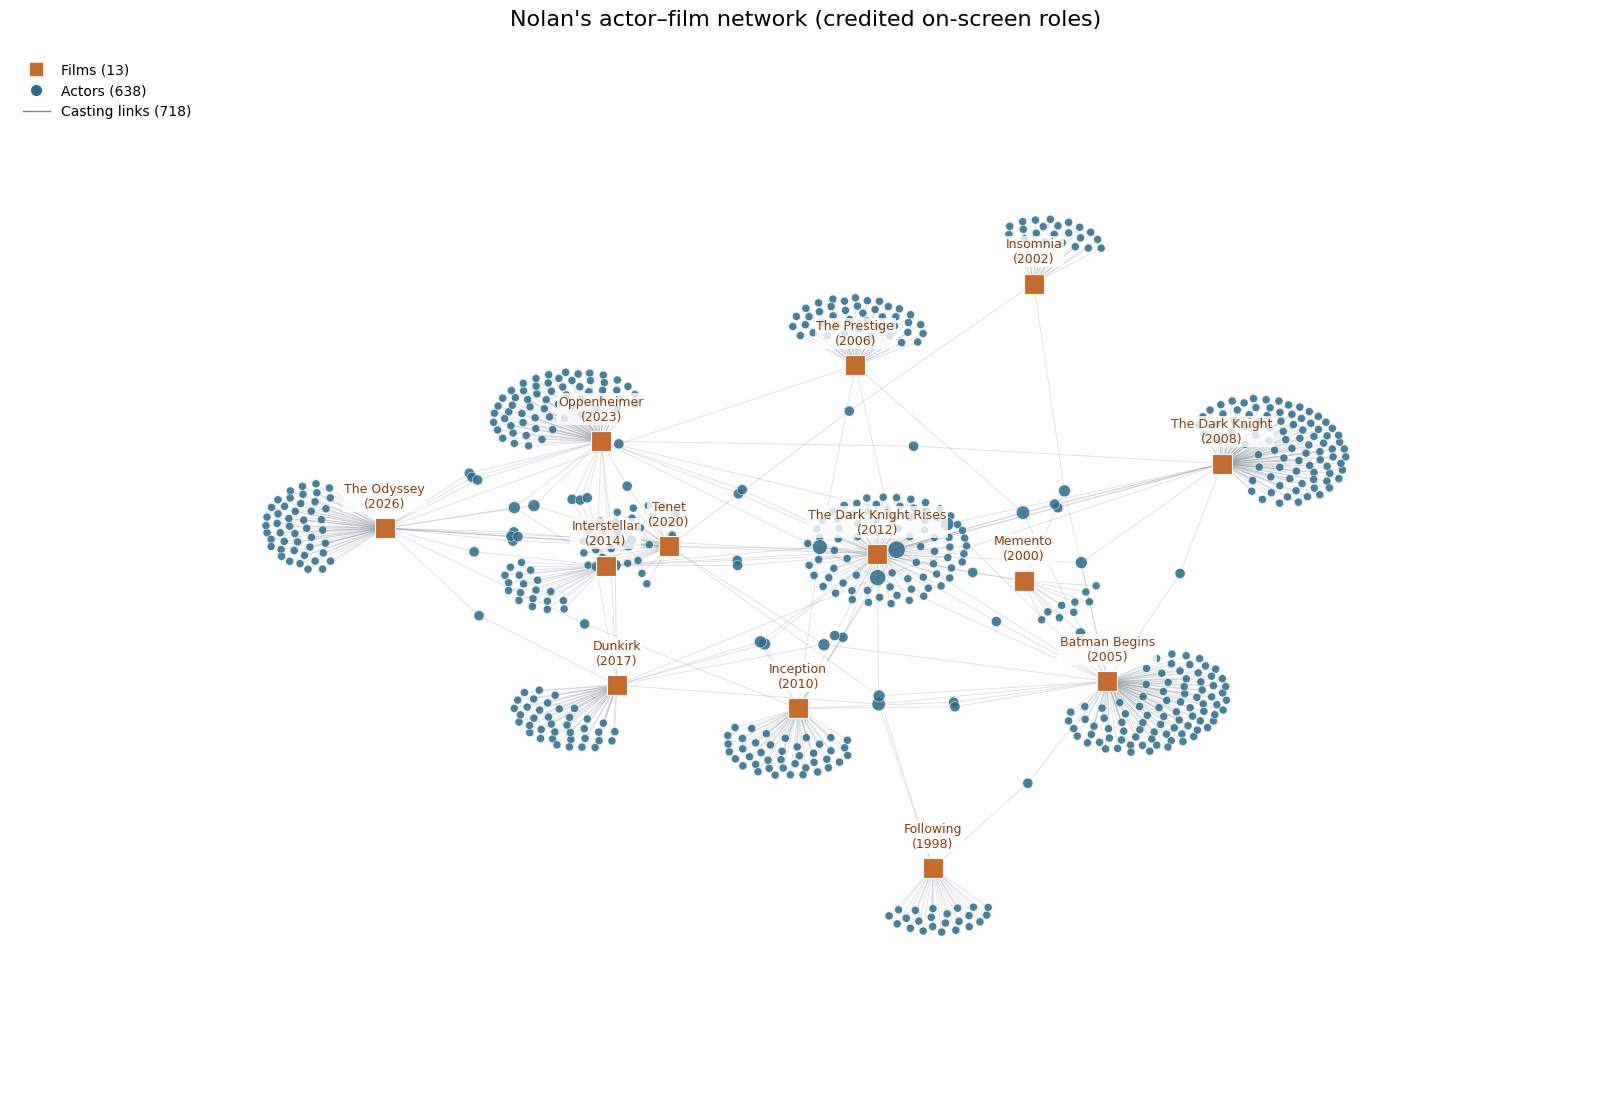

In [3]:
FILM_COLOR = "#c76b2a"
ACTOR_COLOR = "#286b8b"


def draw_cast_network(graph, title, filename, actor_label_count=0, seed=41):
    film_nodes = [n for n in films if n in graph]
    actor_nodes = [n for n in actors if n in graph]
    ordered = nx.Graph()
    ordered.add_nodes_from(sorted(graph))
    ordered.add_edges_from(graph.edges())
    pos = nx.spring_layout(ordered, seed=seed, iterations=220, weight=None)
    fig, ax = plt.subplots(figsize=(16, 11), layout="constrained")

    nx.draw_networkx_edges(graph, pos, ax=ax, edge_color="#7a8591", alpha=0.25, width=0.65)
    nx.draw_networkx_nodes(
        graph, pos, nodelist=actor_nodes, ax=ax,
        node_color=ACTOR_COLOR, node_shape="o",
        node_size=[14 + 20 * graph.degree(n) for n in actor_nodes],
        edgecolors="white", linewidths=0.4, alpha=0.85,
    )
    nx.draw_networkx_nodes(
        graph, pos, nodelist=film_nodes, ax=ax,
        node_color=FILM_COLOR, node_shape="s", node_size=190,
        edgecolors="white", linewidths=0.8,
    )

    # A small offset keeps labels clear of the node markers.
    for node in film_nodes:
        label = textwrap.fill(graph.nodes[node]["label"], width=22)
        label += f"\n({graph.nodes[node]['year']})"
        ax.annotate(
            label, xy=pos[node], xytext=(0, 13), textcoords="offset points",
            ha="center", va="bottom", fontsize=9, color="#823e0c",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.2),
        )

    labelled_actors = sorted(
        actor_nodes, key=lambda n: (-graph.degree(n), graph.nodes[n]["label"])
    )[:actor_label_count]
    for node in labelled_actors:
        ax.annotate(
            graph.nodes[node]["label"], xy=pos[node], xytext=(5, -10),
            textcoords="offset points", ha="left", va="top", fontsize=8,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1),
        )

    legend = [
        Line2D([], [], marker="s", linestyle="none", color=FILM_COLOR,
               markersize=9, label=f"Films ({len(film_nodes)})"),
        Line2D([], [], marker="o", linestyle="none", color=ACTOR_COLOR,
               markersize=7, label=f"Actors ({len(actor_nodes)})"),
        Line2D([], [], color="#7a8591", linewidth=1,
               label=f"Casting links ({graph.number_of_edges()})"),
    ]
    ax.legend(handles=legend, loc="upper left", frameon=False)
    ax.set_title(title, fontsize=16, pad=18)
    ax.margins(0.17)
    ax.set_axis_off()
    # Move a label to a nearby position if it overlaps an earlier label.
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    occupied = []
    for label in ax.texts:
        choices = [
            (*label.get_position(), label.get_ha(), label.get_va()),
            (0, 14, "center", "bottom"), (0, -16, "center", "top"),
            (12, 0, "left", "center"), (-12, 0, "right", "center"),
            (8, 26, "left", "bottom"), (8, -28, "left", "top"),
            (-8, 26, "right", "bottom"), (-8, -28, "right", "top"),
        ]
        for x, y, horizontal, vertical in choices:
            label.set_position((x, y))
            label.set_ha(horizontal)
            label.set_va(vertical)
            bounds = label.get_window_extent(renderer).expanded(1.05, 1.15)
            if not any(bounds.overlaps(other) for other in occupied):
                break
        occupied.append(bounds)

    fig.savefig(FIGURES / filename, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()


draw_cast_network(G, "Nolan's actor–film network (credited on-screen roles)", "nolan_full_network.png")

## Recurring actors

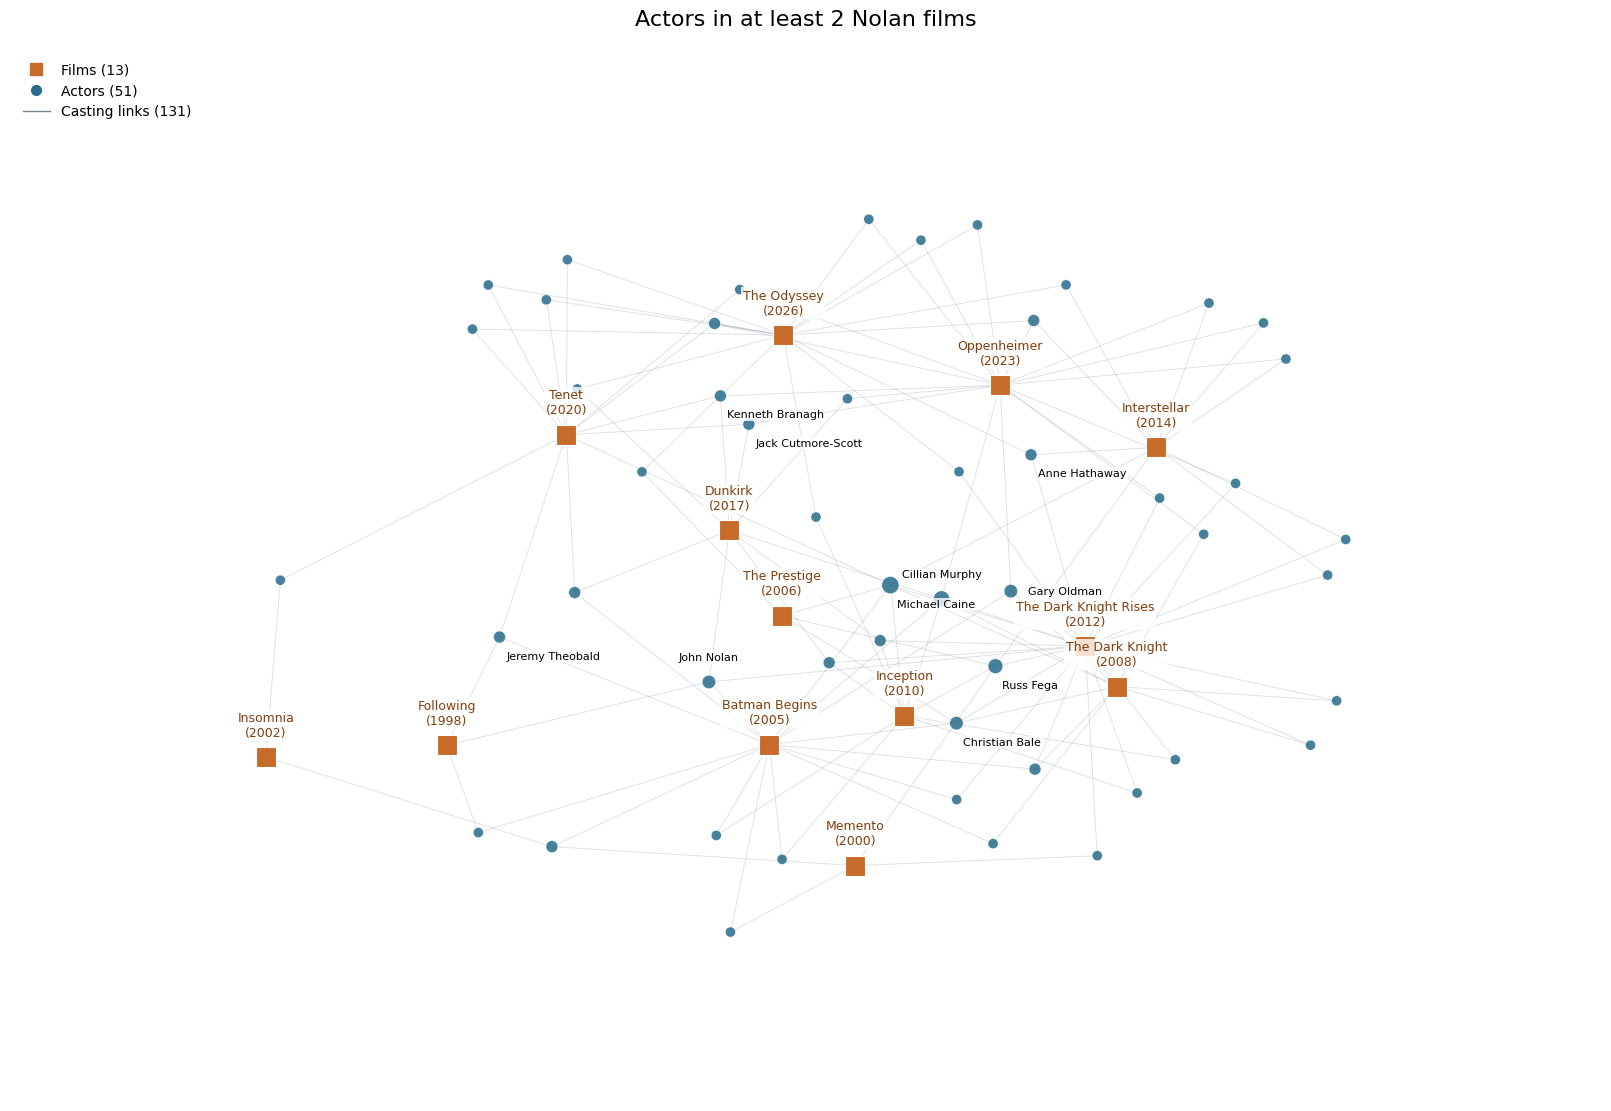

In [4]:
minimum_appearances = 2
recurring_actors = [a for a in actors if G.degree(a) >= minimum_appearances]
recurring = G.subgraph(films + recurring_actors).copy()

draw_cast_network(
    recurring,
    f"Actors in at least {minimum_appearances} Nolan films",
    "nolan_recurring_actors.png",
    actor_label_count=10,
)

In [5]:
leaders = sorted(actors, key=lambda a: (-G.degree(a), G.nodes[a]["label"]))[:15]
rows = ["| Actor | Nolan films |", "| :--- | ---: |"]
rows += [f"| {G.nodes[a]['label']} | {G.degree(a)} |" for a in leaders]
display(Markdown("\n".join(rows)))

| Actor | Nolan films |
| :--- | ---: |
| Michael Caine | 7 |
| Cillian Murphy | 6 |
| Russ Fega | 5 |
| Christian Bale | 4 |
| Gary Oldman | 4 |
| John Nolan | 4 |
| Anne Hathaway | 3 |
| Jack Cutmore-Scott | 3 |
| Jeremy Theobald | 3 |
| Kenneth Branagh | 3 |
| Larry Holden | 3 |
| Matt Damon | 3 |
| Miranda Nolan | 3 |
| Morgan Freeman | 3 |
| Sean Avery | 3 |

In [6]:
from collections import Counter

actor_appearances = {actor: G.degree(actor) for actor in actors}
appearance_distribution = Counter(actor_appearances.values())
film_cast_sizes = {film: G.degree(film) for film in films}

assert sum(appearance_distribution.values()) == len(actors)
assert sum(actor_appearances.values()) == G.number_of_edges()
assert sum(film_cast_sizes.values()) == G.number_of_edges()

single_film_actors = appearance_distribution[1]
multiple_film_actors = sum(count for appearances, count in appearance_distribution.items()
                           if appearances >= 2)
largest_cast = max(films, key=lambda film: film_cast_sizes[film])
smallest_cast = min(films, key=lambda film: film_cast_sizes[film])

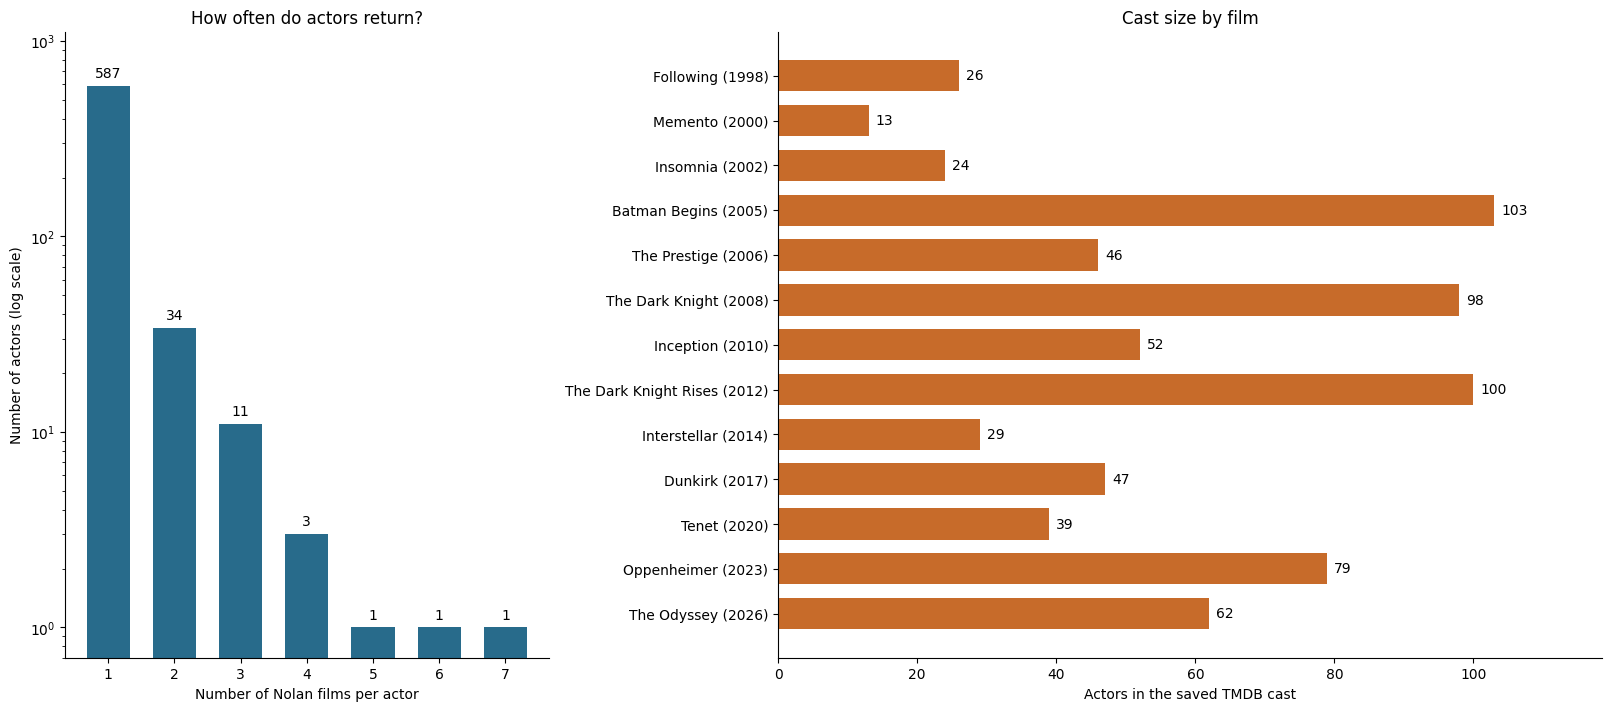

In [7]:
fig, axes = plt.subplots(
    1, 2, figsize=(16, 7), layout="constrained", gridspec_kw={"width_ratios": [1, 1.7]}
)

observed_counts = sorted(appearance_distribution)
actor_bars = axes[0].bar(
    observed_counts, [appearance_distribution[k] for k in observed_counts],
    color=ACTOR_COLOR, width=0.65,
)
axes[0].set_yscale("log")
axes[0].set_ylim(0.7, max(appearance_distribution.values()) * 1.9)
axes[0].set_xticks(observed_counts)
axes[0].bar_label(actor_bars, padding=4)
axes[0].set(title="How often do actors return?",
            xlabel="Number of Nolan films per actor",
            ylabel="Number of actors (log scale)")

film_labels = [textwrap.fill(G.nodes[film]["label"], width=25)
               + f" ({G.nodes[film]['year']})" for film in films]
cast_bars = axes[1].barh(film_labels, [film_cast_sizes[film] for film in films],
                        color=FILM_COLOR, height=0.7)
axes[1].bar_label(cast_bars, padding=5)
axes[1].invert_yaxis()
axes[1].set_xlim(0, max(film_cast_sizes.values()) * 1.15)
axes[1].set(title="Cast size by film", xlabel="Actors in the saved TMDB cast")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIGURES / "nolan_casting_patterns.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

### Which actors connect the films?

**Betweenness centrality** measures how often a node lies on shortest paths
between other nodes. When several equally short paths exist, each receives a
fraction of the credit. We compute exact betweenness on the unweighted actor–film graph
without uncredited, voice and archive-footage credits, then rank the actor nodes.

In [8]:
betweenness = nx.betweenness_centrality(
    G, normalized=True, weight=None, endpoints=False
)
assert all(0 <= value <= 1 for value in betweenness.values())
assert all(betweenness[actor] == 0 for actor in actors if actor_appearances[actor] == 1)

top_connectors = sorted(
    actors, key=lambda actor: (-betweenness[actor], G.nodes[actor]["label"])
)[:10]
table = ["| Actor | Nolan films | Betweenness |",
         "| :--- | ---: | ---: |"]
table += [f"| {G.nodes[actor]['label']} | {actor_appearances[actor]} | {betweenness[actor]:.4f} |"
          for actor in top_connectors]
display(Markdown("\n".join(table)))

print(f"Actors with positive betweenness: {sum(betweenness[a] > 0 for a in actors)} / {len(actors)}")
top_actor = top_connectors[0]
print(f"Highest actor betweenness: {G.nodes[top_actor]['label']} ({betweenness[top_actor]:.4f})")

| Actor | Nolan films | Betweenness |
| :--- | ---: | ---: |
| Michael Caine | 7 | 0.1847 |
| Cillian Murphy | 6 | 0.1464 |
| Gary Oldman | 4 | 0.0690 |
| John Nolan | 4 | 0.0614 |
| Christian Bale | 4 | 0.0598 |
| Larry Holden | 3 | 0.0504 |
| Russ Fega | 5 | 0.0460 |
| Jeremy Theobald | 3 | 0.0291 |
| Anne Hathaway | 3 | 0.0248 |
| Morgan Freeman | 3 | 0.0245 |

Actors with positive betweenness: 51 / 638
Highest actor betweenness: Michael Caine (0.1847)


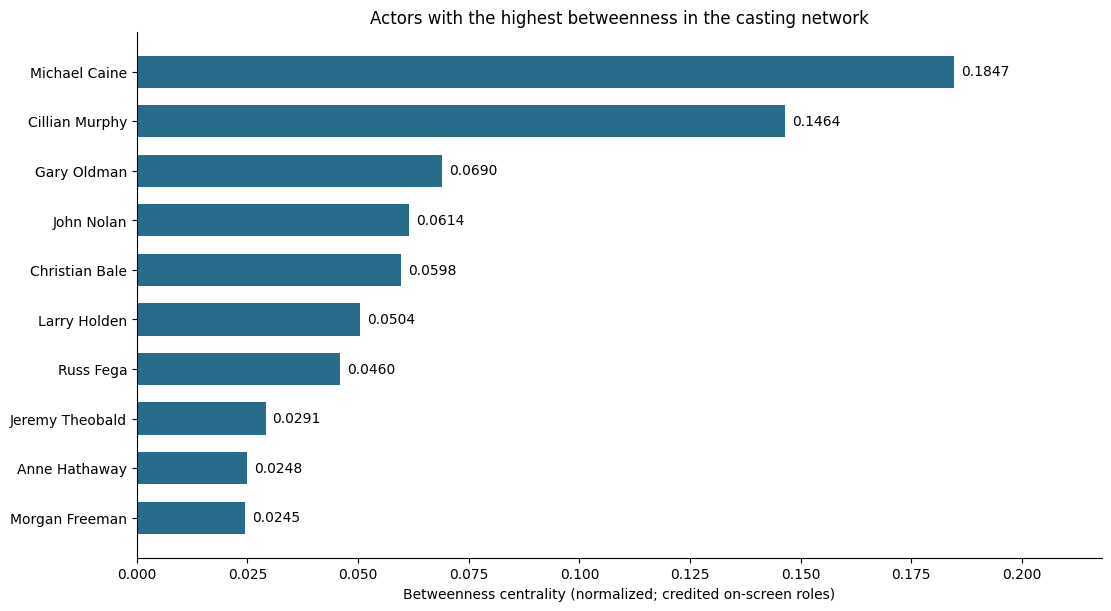

In [9]:
fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
labels = [G.nodes[actor]["label"] for actor in top_connectors]
scores = [betweenness[actor] for actor in top_connectors]
bars = ax.barh(labels, scores, color=ACTOR_COLOR, height=0.65)
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.4f", padding=5)
ax.set_xlim(0, max(scores) * 1.18)
ax.set(title="Actors with the highest betweenness in the casting network",
       xlabel="Betweenness centrality (normalized; credited on-screen roles)")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIGURES / "nolan_actor_betweenness.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

### Who returns, and as whom?

For every actor in **three or more** Nolan films, count the films where they play a **new
character** and the films that **repeat** a character from an earlier Nolan film.
Characters are matched when their credited names share a surname (the last name token
of each alias, after titles are removed). Matching on any token would wrongly merge
*Robert Fischer, Jr.* with *J. Robert Oppenheimer*.

In [10]:
import re
from collections import Counter
from matplotlib.patches import Patch

NAME_STOP = {"commissioner", "detective", "professor", "doctor", "captain", "commander",
             "officer", "sergeant", "lieutenant", "colonel", "general", "major", "agent",
             "inspector", "sir", "lord", "lady", "mister", "miss", "mrs", "young",
             "younger", "old", "the", "man", "woman", "soldier", "jr"}


def name_tokens(character):
    """Last name token of each alias: 'Dr. Jonathan Crane / Scarecrow' -> {crane, scarecrow}.

    Matching on any token would merge characters that only share a first name
    (Robert Fischer, Jr. and J. Robert Oppenheimer).
    """
    text = re.sub(r"\(.*?\)", " ", character or "")
    keys = set()
    for alias in text.split("/"):
        words = [w.lower() for w in re.sub(r"[^A-Za-z\s]", " ", alias).split()
                 if len(w) > 2 and w.lower() not in NAME_STOP]
        if words:
            keys.add(words[-1])
    return keys


def character_ids(credits):
    """Union-find over one actor's credits: credits sharing a name token are one character."""
    parent = list(range(len(credits)))
    def root(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    tokens = [name_tokens(c) for c in credits]
    for i in range(len(credits)):
        for j in range(i):
            if tokens[i] & tokens[j]:
                parent[root(i)] = root(j)
    return [root(i) for i in range(len(credits))]


MIN_FILMS = 3
core = sorted((a for a in actors if a in G and G.degree(a) >= MIN_FILMS),
              key=lambda a: (-G.degree(a), G.nodes[a]["label"]))
status = {}          # (actor, film) -> "new" | "reprise"
for actor in core:
    actor_films = [f for f in films if G.has_edge(actor, f)]          # release order
    ids = character_ids([G.edges[actor, f]["character"] for f in actor_films])
    seen = set()
    for film, cid in zip(actor_films, ids):
        status[actor, film] = "reprise" if cid in seen else "new"
        seen.add(cid)

assert all(G.has_edge(a, f) == ((a, f) in status) for a in core for f in films)
n_reprise = sum(v == "reprise" for v in status.values())
print(f"Actors in >= {MIN_FILMS} films: {len(core)}; links: {len(status)}; "
      f"reprised: {n_reprise}; new characters: {len(status) - n_reprise}")
for actor in core:
    print(f"  {G.nodes[actor]['label']:<20}" + " ".join(
        ("R" if status[actor, f] == "reprise" else "N") if (actor, f) in status else "."
        for f in films))

Actors in >= 3 films: 17; links: 63; reprised: 11; new characters: 52
  Michael Caine       . . . N N R N R N . N . .
  Cillian Murphy      . . . N . R N R . N . N .
  Russ Fega           . N . . N . N N N . . . .
  Christian Bale      . . . N N R . R . . . . .
  Gary Oldman         . . . N . R . R . . . N .
  John Nolan          N . . N . . . R . N . . .
  Anne Hathaway       . . . . . . . N N . . . N
  Jack Cutmore-Scott  . . . . . . . . . N N N .
  Jeremy Theobald     N . . N . . . . . . N . .
  Kenneth Branagh     . . . . . . . . . N N N .
  Larry Holden        . N N N . . . . . . . . .
  Matt Damon          . . . . . . . . N . . N N
  Miranda Nolan       . . . . . . N N . N . . .
  Morgan Freeman      . . . N . R . R . . . . .
  Sean Avery          . . . . . . . . . . N N N
  Tom Hardy           . . . . . . N N . N . . .
  Tom Nolan           . . . N . . . . . N N . .


### The main-cast network (paper Fig. 1)

The layout follows the actor-network figure in *Who is the Centre of the Movie Universe?*
(arXiv 2002.11103): position carries meaning. We use the **main cast** (top ten billing,
the same rule as the role-text analysis) and draw it as a bipartite graph:

- every film is a coloured square on a ring; films that share returning actors are placed
  next to each other (2-opt search minimising the arc length of returning actors' links);
- actors in only one film fan out in grey just outside their film;
- returning actors (two or more films) sit at the average position of their films, pulled
  slightly inward and pushed apart so they do not overlap;
- each link has its film's colour; circle area grows with the number of films.
Labels are placed by trying eight positions and keeping the first one that overlaps nothing.

13 films, 100 main-cast actors: 17 returning, 83 in one film; 130 links
Ring order: Following, Insomnia, Tenet, The Odyssey, Oppenheimer, Dunkirk, Interstellar, Inception, The Dark Knight Rises, The Dark Knight, Batman Begins, The Prestige, Memento


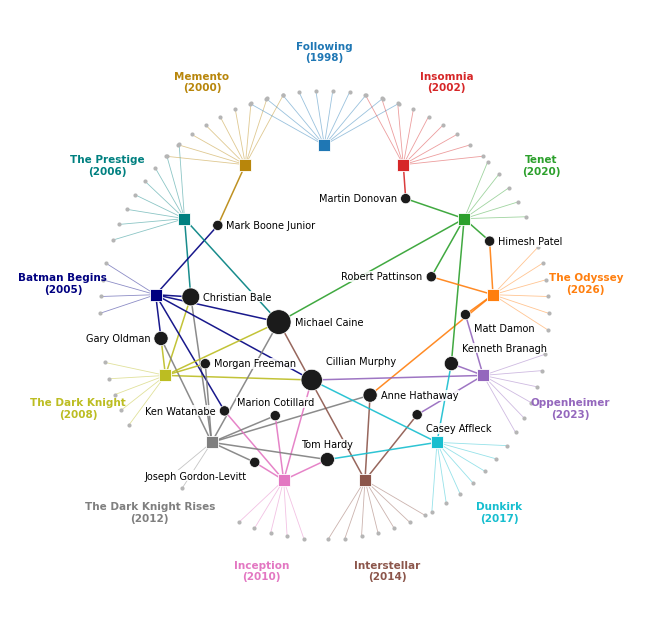

In [11]:
import itertools, math
import numpy as np
from matplotlib.transforms import Bbox

MAIN_BILLING = 10
main = nx.Graph()                                        # main-cast bipartite graph
for a, f, d in G.edges(data=True):
    if int(d["cast_order"]) < MAIN_BILLING:
        actor, film = (a, f) if G.nodes[a]["node_type"] == "actor" else (f, a)
        main.add_edge(actor, film)
label = lambda n: G.nodes[n]["label"]
ring_films = [f for f in films if f in main]
cast = sorted((n for n in main if G.nodes[n]["node_type"] == "actor"), key=label)
returning = [a for a in cast if main.degree(a) >= 2]
one_film = [a for a in cast if main.degree(a) == 1]
print(f"{len(ring_films)} films, {len(cast)} main-cast actors: {len(returning)} returning, "
      f"{len(one_film)} in one film; {main.number_of_edges()} links")

def arc_cost(order):                                     # total arc between films sharing an actor
    angle = {f: 2 * math.pi * i / len(order) for i, f in enumerate(order)}
    total = 0.0
    for a in returning:
        for u, v in itertools.combinations([angle[f] for f in main[a]], 2):
            d = abs(u - v)
            total += min(d, 2 * math.pi - d)
    return total

order, best, improved = ring_films[:], arc_cost(ring_films), True
while improved:                                          # 2-opt: reverse segments while it helps
    improved = False
    for i in range(1, len(order)):
        for j in range(i + 1, len(order) + 1):
            candidate = order[:i] + order[i:j][::-1] + order[j:]
            c = arc_cost(candidate)
            if c < best - 1e-9:
                order, best, improved = candidate, c, True
print("Ring order:", ", ".join(label(f) for f in order))

angle = {f: math.pi / 2 - 2 * math.pi * i / len(order) for i, f in enumerate(order)}
hub = {f: np.array([math.cos(angle[f]), math.sin(angle[f])]) for f in order}
pos = dict(hub)
for f in order:                                          # one-film actors fan out beyond their film
    fan = [a for a in one_film if main.has_edge(a, f)]
    for k, a in enumerate(fan):
        t = angle[f] + (k - (len(fan) - 1) / 2) * 0.075
        pos[a] = np.array([1.32 * math.cos(t), 1.32 * math.sin(t)])
# Returning actors: spring layout with every film square and one-film actor held fixed,
# so each returning actor is pulled toward its own films and pushed away from the others.
springs = nx.Graph()
springs.add_nodes_from(order)
springs.add_nodes_from(returning)
springs.add_edges_from((a, f) for a in returning for f in main[a])
start = dict(hub)
start.update({a: np.mean([hub[f] for f in main[a]], axis=0) * 0.8 for a in returning})
placed = nx.spring_layout(springs, pos=start, fixed=order, k=0.42, iterations=500, seed=1)
for a in returning:
    pos[a] = np.asarray(placed[a], dtype=float)
    r = np.linalg.norm(pos[a])                           # stay inside the ring of film squares
    if r > 0.85:
        pos[a] = pos[a] * 0.85 / r
MIN_GAP = 0.3
rng = np.random.default_rng(2805)
for _ in range(400):                                     # then enforce a minimum spacing
    for i, a in enumerate(returning):
        for b in returning[i + 1:]:
            d = pos[a] - pos[b]
            dist = np.linalg.norm(d)
            if dist < MIN_GAP:                           # identical film sets land on one point
                direction = d / dist if dist > 1e-9 else rng.normal(size=2) / np.sqrt(2)
                push = direction * (MIN_GAP - dist) / 2
                pos[a], pos[b] = pos[a] + push, pos[b] - push
        for f in order:                                  # and keep actors off the film squares
            d = pos[a] - hub[f]
            dist = np.linalg.norm(d)
            if dist < 0.2:
                pos[a] = pos[a] + d / dist * (0.2 - dist)

COLOURS = ["#1f77b4", "#d62728", "#2ca02c", "#ff7f0e", "#9467bd", "#17becf", "#8c564b",
           "#e377c2", "#7f7f7f", "#bcbd22", "#000080", "#008080", "#b8860b"]
colour = {f: COLOURS[i] for i, f in enumerate(order)}
size = lambda a: 18 * main.degree(a) ** 1.6

fig, ax = plt.subplots(figsize=(7.0, 6.2), layout="constrained")
for a in cast:
    for f in main[a]:
        ret = a in returning
        ax.plot(*zip(pos[a], hub[f]), color=colour[f], lw=1.1 if ret else 0.6,
                alpha=0.9 if ret else 0.45, zorder=2 if ret else 1)
ax.scatter([pos[a][0] for a in one_film], [pos[a][1] for a in one_film], s=9, color="#b5b5b5", lw=0, zorder=3)
ax.scatter([pos[a][0] for a in returning], [pos[a][1] for a in returning], s=[size(a) for a in returning],
           color="#1b1b1b", edgecolor="white", lw=0.5, zorder=4)
for f in order:
    ax.scatter(*hub[f], s=70, marker="s", color=colour[f], edgecolor="white", lw=0.6, zorder=6)
    ax.text(1.55 * math.cos(angle[f]), 1.55 * math.sin(angle[f]), f"{label(f)}\n({G.nodes[f]['year']})",
            ha="center", va="center", fontsize=7.5, color=colour[f], fontweight="bold")
ax.set_xlim(-1.85, 1.85)
ax.set_ylim(-1.8, 1.8)
ax.set_aspect("equal")
ax.axis("off")

fig.canvas.draw()                                        # collision-free actor labels
renderer = fig.canvas.get_renderer()
taken = [t.get_window_extent(renderer).expanded(1.05, 1.1) for t in ax.texts]
for f in order:
    x, y = ax.transData.transform(hub[f])
    taken.append(Bbox([[x - 6, y - 6], [x + 6, y + 6]]))
for a in returning:
    x, y = ax.transData.transform(pos[a])
    r = math.sqrt(size(a)) * 0.75 + 1
    taken.append(Bbox([[x - r, y - r], [x + r, y + r]]))
segments = [(ax.transData.transform(pos[a]), ax.transData.transform(hub[f]))
            for a in cast for f in main[a]]
def links_under(box):                                    # sampled points of links inside the box
    hits = 0
    for p, q in segments:
        for t in np.linspace(0.05, 0.95, 25):
            x, y = p + t * (q - p)
            if box.x0 <= x <= box.x1 and box.y0 <= y <= box.y1:
                hits += 1
                break
    return hits

for a in sorted(returning, key=lambda a: -main.degree(a)):
    r = math.sqrt(size(a)) / 2 + 2.5
    own = ax.transData.transform(pos[a])
    spots = [(r, 0, "left", "center"), (-r, 0, "right", "center"), (0, r, "center", "bottom"),
             (0, -r, "center", "top"), (r, r, "left", "bottom"), (-r, r, "right", "bottom"),
             (r, -r, "left", "top"), (-r, -r, "right", "top")]
    best = None
    for dx, dy, ha, va in spots:
        t = ax.annotate(label(a), pos[a], xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                        fontsize=7, zorder=5, bbox=dict(boxstyle="square,pad=0.05", fc="white", ec="none", alpha=0.85))
        box = t.get_window_extent(renderer).expanded(1.04, 1.08)
        t.remove()
        if any(box.overlaps(o) and not o.contains(*own) for o in taken):
            continue
        score = links_under(box) + (0.5 if dx and dy else 0)       # slight preference for side/top/bottom
        if best is None or score < best[0]:
            best = (score, dx, dy, ha, va, box)
    if best is None:
        print("No free label position for", label(a))
        continue
    _, dx, dy, ha, va, box = best
    ax.annotate(label(a), pos[a], xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                fontsize=7, zorder=5, bbox=dict(boxstyle="square,pad=0.05", fc="white", ec="none", alpha=0.85))
    taken.append(box)
assert all(np.isfinite(pos[a]).all() for a in cast), "a node position is not finite"
fig.savefig(FIGURES / "nolan_main_cast_network.png", dpi=300, facecolor="white")
fig.savefig(FIGURES / "nolan_main_cast_network.pdf", facecolor="white")
plt.show()


## Film-to-film network: shared actors

We now project the actor–film graph (credited on-screen roles) onto its film nodes. Each node is a
Nolan film. Two films are connected when at least one actor has a casting credit
in both. Each actor counts once per film pair, regardless of character or billing.
All films are retained, including any without a shared actor.

We store two measures for each edge, using the casts $C_i$ and $C_j$:

- **Shared actors:** $|C_i \cap C_j|$. This is also the default edge `weight`.
- **Jaccard overlap:** $|C_i \cap C_j| / |C_i \cup C_j|$.
  This accounts for cast size. For example, two casts of 10 actors sharing two
  actors have an overlap of $2 / 18 = 11.1\%$.

These are cast-overlap measures. They do not measure shared scenes or character
similarity. The cast inclusion rules are the same as in the full network above;
the recurring-actor filter does not change these calculations.

In [12]:
from itertools import combinations
import json

cast_sets = {film: set(G.neighbors(film)) for film in films}
film_projection = nx.Graph(
    name="Nolan film network: shared actors",
    source_graph=GRAPH_FILE.name,
    weight_definition="Number of distinct actors credited in both films",
    jaccard_definition="Shared actors divided by distinct actors in either cast",
)
film_projection.add_nodes_from(
    (film, {**G.nodes[film], "cast_size": len(cast_sets[film])})
    for film in films
)

for film_a, film_b in combinations(films, 2):
    shared = cast_sets[film_a] & cast_sets[film_b]
    if not shared:
        continue
    shared_ids = sorted(shared, key=lambda actor: G.nodes[actor]["label"])
    film_projection.add_edge(
        film_a, film_b,
        weight=len(shared),
        shared_actor_count=len(shared),
        jaccard=len(shared) / len(cast_sets[film_a] | cast_sets[film_b]),
        shared_actor_ids=json.dumps(shared_ids),
        shared_actor_names=json.dumps([G.nodes[actor]["label"] for actor in shared_ids]),
    )

# Check the raw counts against NetworkX's standard bipartite projection.
reference = nx.algorithms.bipartite.weighted_projected_graph(G, films)
assert set(film_projection) == set(films)
assert film_projection.number_of_edges() == reference.number_of_edges()
assert all(d["weight"] == reference[a][b]["weight"]
           for a, b, d in film_projection.edges(data=True))
assert nx.number_of_selfloops(film_projection) == 0

projection_file = GRAPH_FILE.parent / "nolan_film_projection.graphml"
nx.write_graphml(film_projection, projection_file)
print(f"Film nodes: {film_projection.number_of_nodes()}")
print(f"Film pairs sharing actors: {film_projection.number_of_edges()}")
print(f"Connected components: {nx.number_connected_components(film_projection)}")
print(f"Saved: {projection_file.name}")

Film nodes: 13
Film pairs sharing actors: 52
Connected components: 1
Saved: nolan_film_projection.graphml


### Compare shared counts and cast overlap

Both panels show **all links** and use the same circular layout, with films in
release-year order counterclockwise from the right. Node positions are fixed for
comparison. The legend in each panel gives its own line-width scale; the two
panels use different units. Node size is constant.

The Jaccard panel uses all actors in each cast as its denominator, including
actors who appear in only one Nolan film.

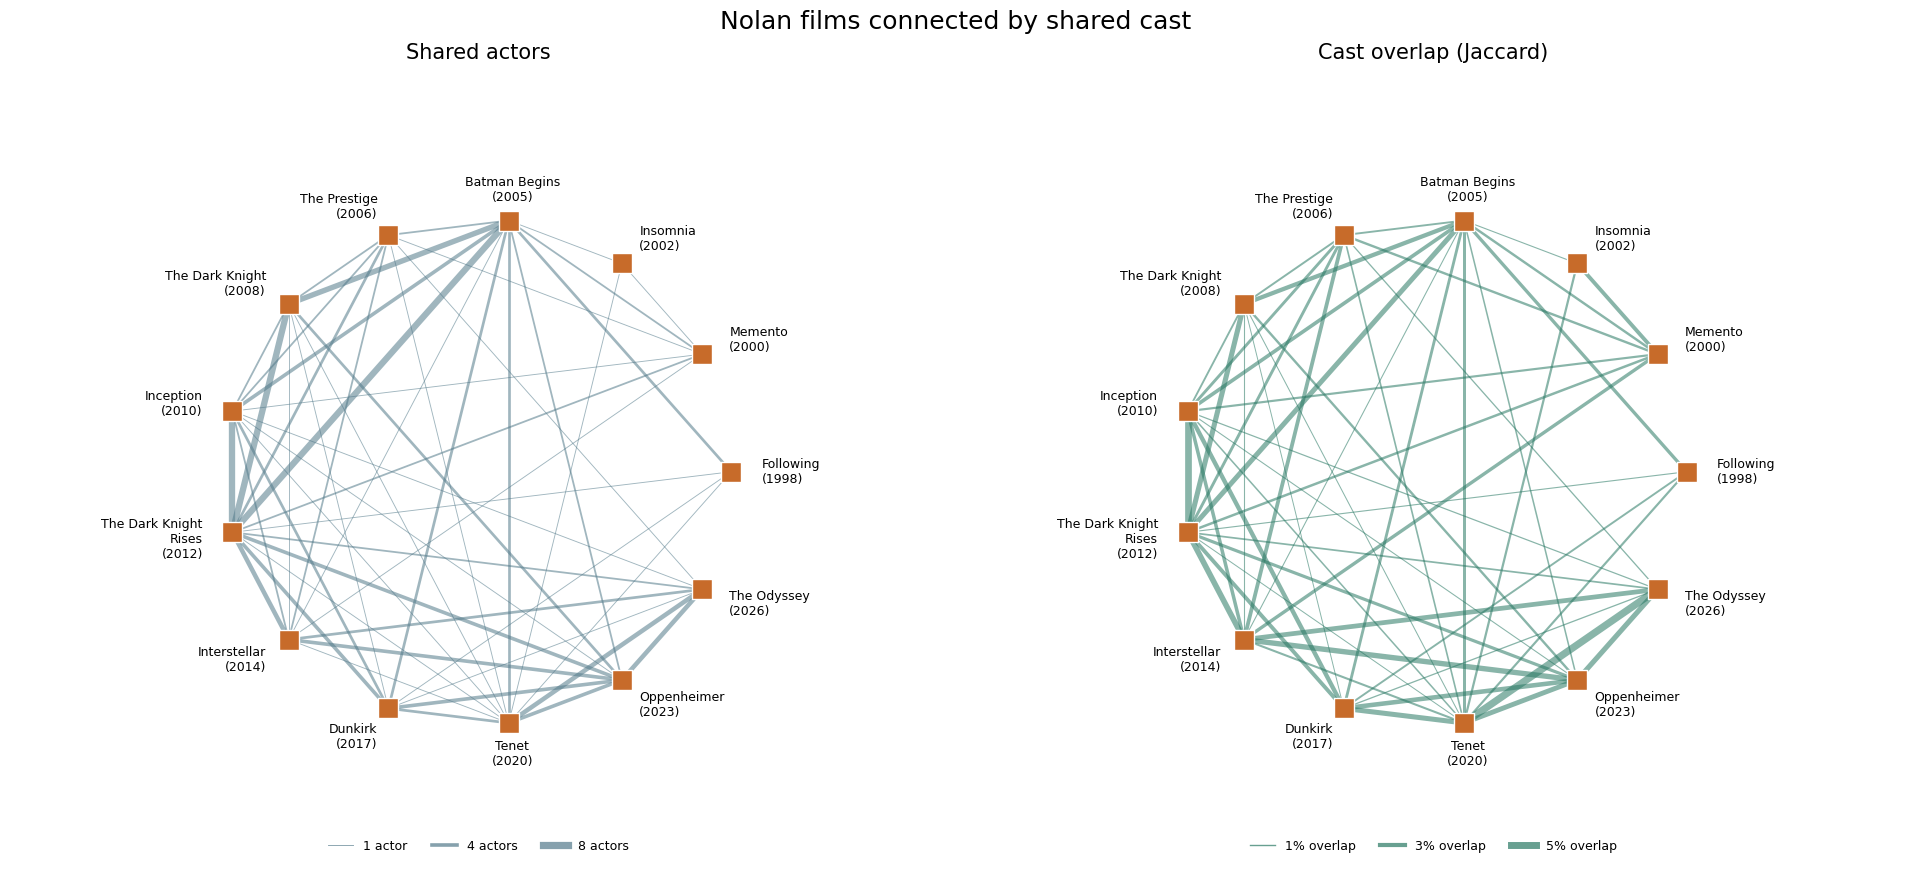

In [13]:
positions = nx.circular_layout(films)
fig, axes = plt.subplots(1, 2, figsize=(19, 9), layout="constrained")
panels = [
    (axes[0], "shared_actor_count", "Shared actors", "#537a8a", 0.65,
     [(1, "1 actor"), (4, "4 actors"), (8, "8 actors")]),
    (axes[1], "jaccard", "Cast overlap (Jaccard)", "#287863", 100,
     [(0.01, "1% overlap"), (0.03, "3% overlap"), (0.05, "5% overlap")]),
]

for ax, measure, title, color, width_scale, examples in panels:
    edges = sorted(film_projection.edges(), key=lambda e: film_projection.edges[e][measure])
    nx.draw_networkx_edges(
        film_projection, positions, edgelist=edges, ax=ax,
        width=[width_scale * film_projection.edges[e][measure] for e in edges],
        edge_color=color, alpha=0.55,
    )
    nx.draw_networkx_nodes(
        film_projection, positions, ax=ax, node_shape="s", node_size=200,
        node_color=FILM_COLOR, edgecolors="white", linewidths=1,
    )
    for film in films:
        x, y = positions[film]
        label = textwrap.fill(G.nodes[film]["label"], width=19)
        label += f"\n({G.nodes[film]['year']})"
        ax.annotate(
            label, xy=(x, y), xytext=(22 * x, 22 * y),
            textcoords="offset points",
            ha="left" if x > 0.2 else "right" if x < -0.2 else "center",
            va="center", fontsize=9,
        )

    handles = [Line2D([], [], color=color, alpha=0.7,
                      linewidth=width_scale * value, label=label)
               for value, label in examples]
    ax.legend(handles=handles, loc="lower center", ncol=3, frameon=False,
              handlelength=2, fontsize=9)
    ax.set_title(title, fontsize=15, pad=15)
    ax.set_xlim(-1.85, 1.85)
    ax.set_ylim(-1.55, 1.55)
    ax.set_aspect("equal")
    ax.set_axis_off()

fig.suptitle("Nolan films connected by shared cast", fontsize=18)
fig.savefig(FIGURES / "nolan_film_projection.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

In [14]:
pair_rows = [
    {
        "film_a": G.nodes[a]["label"],
        "film_b": G.nodes[b]["label"],
        "shared": d["shared_actor_count"],
        "jaccard": d["jaccard"],
    }
    for a, b, d in film_projection.edges(data=True)
]

for measure, title in [
    ("shared", "Pairs with the most shared actors"),
    ("jaccard", "Pairs with the largest cast overlap"),
]:
    ranked = sorted(pair_rows, key=lambda row: (-row[measure], row["film_a"], row["film_b"]))[:10]
    table = [f"### {title}", "",
             "| Film A | Film B | Shared actors | Jaccard overlap |",
             "| :--- | :--- | ---: | ---: |"]
    table += [f"| {row['film_a']} | {row['film_b']} | {row['shared']} | {row['jaccard']:.2%} |"
              for row in ranked]
    display(Markdown("\n".join(table)))

### Pairs with the most shared actors

| Film A | Film B | Shared actors | Jaccard overlap |
| :--- | :--- | ---: | ---: |
| Batman Begins | The Dark Knight Rises | 7 | 3.57% |
| Inception | The Dark Knight Rises | 7 | 4.83% |
| The Dark Knight | The Dark Knight Rises | 7 | 3.66% |
| Batman Begins | The Dark Knight | 6 | 3.08% |
| Oppenheimer | The Odyssey | 5 | 3.68% |
| Tenet | The Odyssey | 5 | 5.21% |
| The Dark Knight Rises | Interstellar | 5 | 4.03% |
| Batman Begins | Inception | 4 | 2.65% |
| Dunkirk | Oppenheimer | 4 | 3.28% |
| Interstellar | Oppenheimer | 4 | 3.85% |

### Pairs with the largest cast overlap

| Film A | Film B | Shared actors | Jaccard overlap |
| :--- | :--- | ---: | ---: |
| Tenet | The Odyssey | 5 | 5.21% |
| Inception | The Dark Knight Rises | 7 | 4.83% |
| The Dark Knight Rises | Interstellar | 5 | 4.03% |
| Interstellar | Oppenheimer | 4 | 3.85% |
| Oppenheimer | The Odyssey | 5 | 3.68% |
| The Dark Knight | The Dark Knight Rises | 7 | 3.66% |
| Dunkirk | Tenet | 3 | 3.61% |
| Batman Begins | The Dark Knight Rises | 7 | 3.57% |
| Tenet | Oppenheimer | 4 | 3.51% |
| Interstellar | The Odyssey | 3 | 3.41% |

### Inspect the actors behind a link

Change the two film titles below and rerun the cell to inspect another pair.
The cast sizes and actor names come from the same graph used in both panels.

In [15]:
film_a_title = "Batman Begins"
film_b_title = "The Dark Knight Rises"

film_by_title = {G.nodes[film]["label"]: film for film in films}
film_a, film_b = film_by_title[film_a_title], film_by_title[film_b_title]
shared = cast_sets[film_a] & cast_sets[film_b]
union = cast_sets[film_a] | cast_sets[film_b]
print(f"{film_a_title}: {len(cast_sets[film_a])} actors in the saved TMDB cast")
print(f"{film_b_title}: {len(cast_sets[film_b])} actors in the saved TMDB cast")
print(f"Shared actors: {len(shared)}")
print(f"Jaccard overlap: {len(shared) / len(union):.2%}")
print("\nShared cast:")
for actor in sorted(shared, key=lambda actor: G.nodes[actor]["label"]):
    print(f"- {G.nodes[actor]['label']}")

Batman Begins: 103 actors in the saved TMDB cast
The Dark Knight Rises: 100 actors in the saved TMDB cast
Shared actors: 7
Jaccard overlap: 3.57%

Shared cast:
- Christian Bale
- Cillian Murphy
- Gary Oldman
- John Nolan
- Liam Neeson
- Michael Caine
- Morgan Freeman


The notebook saves its plots in `Final project/figures/` and the film projection
in `data/nolan/graphs/nolan_film_projection.graphml`. The saved projection includes
both edge measures and the identities of shared actors. Its default `weight`
attribute is the shared-actor count; select `jaccard` when analysing normalized
overlap.

These views show casting relationships. Testing whether Nolan casts actors in
their typical roles will also require the earlier-film extension and the later
text analysis.